# Multimodal Identification of Informative Social Media Posts for Disaster Response (CrisisMMD v2.0)

## Setup

In [ ]:
!pip install -q datasets transformers torchvision scikit-learn huggingface_hub
import os, re, html, time, copy, json, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn as nn
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from sklearn import metrics as skm
from IPython.display import display
warnings.filterwarnings("ignore")

SEEDS = [42, 43, 44]
DATA, OUT = Path("/content/data"), Path("/content/outputs")
for d in [DATA, OUT / "figures", OUT / "tables"]: d.mkdir(parents=True, exist_ok=True)
def set_seed(s): random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
def savefig(name): plt.savefig(OUT / "figures" / f"{name}.png", dpi=200, bbox_inches="tight"); plt.show()
set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu"); print("device:", device)


device: cuda


 ## Load CrisisMMD v2.0 (informative task) + download the image files

In [ ]:
from datasets import load_dataset
from huggingface_hub import snapshot_download
ds = load_dataset("QCRI/CrisisMMD", "informative")
img_root = Path(snapshot_download("QCRI/CrisisMMD", repo_type="dataset", allow_patterns=["data_image/**"],
                                  local_dir=DATA / "hf_raw", max_workers=16))
rows = []
for split in ds:
    d = ds[split]
    names = getattr(d.features["label"], "names", None)
    if "image" in d.column_names: d = d.remove_columns(["image"])
    for ex in d:
        lab = names[ex["label"]] if names is not None and isinstance(ex["label"], int) else ex["label"]
        rows.append(dict(split=split, event=ex["event_name"], tweet_id=str(ex["tweet_id"]), image_id=ex["image_id"],
                         text=ex["tweet_text"] or "", path=str(img_root / ex["image_path"]),
                         label=str(lab).lower().replace(" ", "_")))
df = pd.DataFrame(rows)
df["y"] = (df.label == "informative").astype(int)
print(df.groupby("split").size(), f"\nimage files found: {df.path.map(os.path.exists).sum()} / {len(df)}")


README.md:   0%|          | 0.00/12.4k [00:00<?, ?B/s]

informative/train.json: reconstructing file:   0%|          |  0.00B / 5.49MB            

informative/train.json: downloading bytes:           |  0.00B            

informative/dev.json: reconstructing file:   0%|          |  0.00B /  906kB            

informative/dev.json: downloading bytes:           |  0.00B            

informative/test.json: reconstructing file:   0%|          |  0.00B /  905kB            

... (3 outputs left out)

Generating test split:   0%|          | 0/2237 [00:00<?, ? examples/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18082 files:   0%|          | 0/18082 [00:00<?, ?it/s]

split
dev       2237
test      2237
train    13608
dtype: int64 
image files found: 18082 / 18082


## Data quality assessment

checking images:   0%|          | 0/18082 [00:00<?, ?it/s]

,value
records,18082.0
missing text,0.0
missing / corrupt images,0.0
exact duplicate rows,0.0
rows with duplicated text,3169.0
...from tweets with several images,3169.0
"same tweet, images with different labels",283.0
mean words per tweet,13.8


label,informative,not_informative,All,informative_%
split,,,,
dev,1407,830,2237,62.896737
test,1373,864,2237,61.376844
train,8341,5267,13608,61.294827
All,11121,6961,18082,61.503152


label,informative,not_informative,All
event,,,
All,11121,6961,18082
hurricane_maria,2526,2030,4556
hurricane_irma,2889,1615,4504
hurricane_harvey,2892,1542,4434
california_wildfires,1127,462,1589
mexico_earthquake,936,444,1380
srilanka_floods,315,707,1022
iraq_iran_earthquake,436,161,597


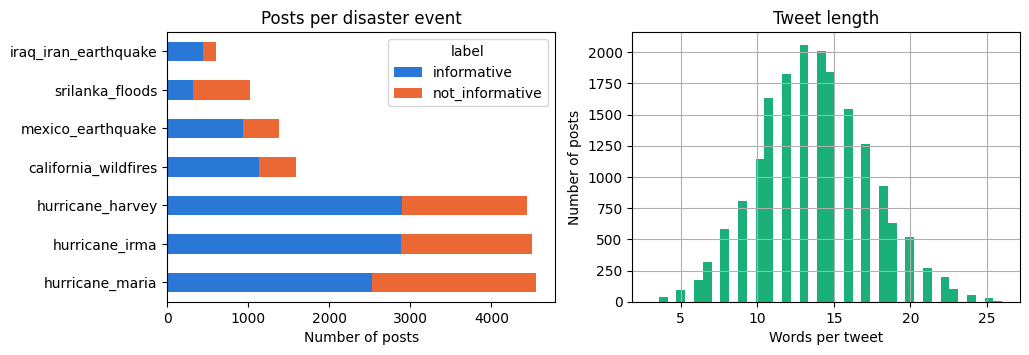

In [ ]:
def image_ok(p):
    try:
        with Image.open(p) as im: im.verify()
        return True
    except Exception: return False
df["image_ok"] = [image_ok(p) for p in tqdm(df.path, desc="checking images")]

quality = pd.Series({
    "records": len(df),
    "missing text": (df.text.str.strip() == "").sum(),
    "missing / corrupt images": (~df.image_ok).sum(),
    "exact duplicate rows": df.duplicated(["tweet_id", "image_id"]).sum(),
    "rows with duplicated text": df.text.duplicated(keep=False).sum(),
    "  ...from tweets with several images": df.tweet_id.duplicated(keep=False).sum(),
    "same tweet, images with different labels": (df.groupby("tweet_id").y.nunique() > 1).sum(),
    "mean words per tweet": round(df.text.str.split().str.len().mean(), 1)}, name="value")
display(quality.to_frame()); quality.to_csv(OUT / "tables" / "data_quality.csv")

balance = pd.crosstab(df.split, df.label, margins=True); balance["informative_%"] = 100 * balance.informative / balance.All
events = pd.crosstab(df.event, df.label, margins=True).sort_values("All", ascending=False)
display(balance, events); balance.to_csv(OUT / "tables" / "class_balance.csv"); events.to_csv(OUT / "tables" / "events.csv")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
events.drop("All").drop(columns="All").plot.barh(stacked=True, ax=ax[0], color=["#2a78d6", "#eb6834"])
ax[0].set(xlabel="Number of posts", ylabel="", title="Posts per disaster event")
df.text.str.split().str.len().hist(bins=40, ax=ax[1], color="#1baf7a")
ax[1].set(xlabel="Words per tweet", ylabel="Number of posts", title="Tweet length")
savefig("data_quality")


## Preprocessing (text cleaning, duplicate removal, token length)

In [ ]:
def clean_text(t):
    t = html.unescape(str(t))
    if "â" in t or "Ã" in t:
        try: t = t.encode("cp1252").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError): pass
    t = re.sub(r"^RT @\w+:?\s*", "", t)
    t = re.sub(r"https?://\S+", " ", t)
    t = re.sub(r"@\w+", "@user", t)
    t = re.sub(r"#(\w+)", lambda m: re.sub(r"([a-z])([A-Z])", r"\1 \2", m.group(1)), t)
    return re.sub(r"\s+", " ", t).strip() or "[empty]"
df["text_clean"] = df.text.map(clean_text)
display(df.sample(5, random_state=1)[["text", "text_clean"]])

df = df[df.image_ok].copy()
train = df[df.split == "train"].drop_duplicates(["text_clean", "image_id"])
eval_keys = set(df[df.split != "train"].text_clean + "|" + df[df.split != "train"].image_id)
train = train[~(train.text_clean + "|" + train.image_id).isin(eval_keys)]
S = {"train": train.reset_index(drop=True),
     "dev": df[df.split == "dev"].reset_index(drop=True), "test": df[df.split == "test"].reset_index(drop=True)}
Y = {s: d.y.to_numpy() for s, d in S.items()}
print({s: len(d) for s, d in S.items()}, f"(removed {(df.split == 'train').sum() - len(train)} train duplicates)")

from transformers import AutoTokenizer, AutoModel
tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
lens = np.array([len(x) for x in tok(S["train"].text_clean.tolist())["input_ids"]])
MAX_LEN = int(np.ceil(np.percentile(lens, 95) / 8) * 8)
print(f"95% of tweets fit in {MAX_LEN} tokens -> MAX_LEN = {MAX_LEN}")


,text,text_clean
7768,Combined Harvey &amp; Irma losses could strain...,Combined Harvey & Irma losses could strain som...
4111,@rileymancr St Thomas before Irma https://t.co...,@user St Thomas before Irma
3261,Multinewmedia thanks @mylkldelectric for their...,Multinewmedia thanks @user for their amazing r...
1684,Have you ever been so happy to see a blocking ...,Have you ever been so happy to see a blocking ...
13792,"#Houston cop with cancer rescued nearly 1,500 ...","Houston cop with cancer rescued nearly 1,500 H..."


{'train': 13608, 'dev': 2237, 'test': 2237} (removed 0 train duplicates)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

95% of tweets fit in 32 tokens -> MAX_LEN = 32


##  Feature extraction:

In [ ]:
from torchvision import transforms as T
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
img_tf = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(),
                    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])   # ImageNet normalisation

@torch.no_grad()
def text_features(texts, bs=128):
    model = AutoModel.from_pretrained("distilbert-base-uncased").to(device).eval(); out = []
    for i in tqdm(range(0, len(texts), bs), desc="DistilBERT"):
        enc = tok(texts[i:i + bs], padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(device)
        h = model(**enc).last_hidden_state
        mask = enc["attention_mask"].unsqueeze(-1)
        out.append(((h * mask).sum(1) / mask.sum(1)).cpu().numpy())      # mean pooling -> 768-d
    return np.concatenate(out)

class ImageData(torch.utils.data.Dataset):
    def __init__(self, paths): self.paths = list(paths)
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im: return img_tf(ImageOps.exif_transpose(im).convert("RGB"))

@torch.no_grad()
def image_features(paths):
    model = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1); model.classifier = nn.Identity()
    model = model.to(device).eval(); out = []
    for x in tqdm(torch.utils.data.DataLoader(ImageData(paths), batch_size=64, num_workers=2), desc="EfficientNet-B0"):
        out.append(model(x.to(device)).cpu().numpy())                    # 1280-d
    return np.concatenate(out)

X, EXTRACT_TIME = {}, {}
for s, d in S.items():
    t0 = time.time(); xt = text_features(d.text_clean.tolist()); EXTRACT_TIME[f"text_{s}"] = time.time() - t0
    t0 = time.time(); xv = image_features(d.path.tolist());     EXTRACT_TIME[f"image_{s}"] = time.time() - t0
    X[s] = {"text": xt, "image": xv}
mu = {m: X["train"][m].mean(0) for m in ["text", "image"]}; sd = {m: X["train"][m].std(0) + 1e-6 for m in ["text", "image"]}
X = {s: {m: torch.tensor((X[s][m] - mu[m]) / sd[m], dtype=torch.float32, device=device) for m in X[s]} for s in X}  # standardise (train stats)
print({m: tuple(v.shape) for m, v in X["train"].items()}, {k: f"{v:.0f}s" for k, v in EXTRACT_TIME.items()})


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT:   0%|          | 0/107 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 61.0MB/s]


EfficientNet-B0:   0%|          | 0/213 [00:00<?, ?it/s]

## Models and training loop

In [ ]:
class TextOnly(nn.Module):
    def __init__(s): super().__init__(); s.net = nn.Sequential(nn.Linear(768, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 1))
    def forward(s, b): return s.net(b["text"]).squeeze(-1)

class ImageOnly(nn.Module):
    def __init__(s): super().__init__(); s.net = nn.Sequential(nn.Linear(1280, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 1))
    def forward(s, b): return s.net(b["image"]).squeeze(-1)

class EarlyFusion(nn.Module):
    def __init__(s): super().__init__(); s.net = nn.Sequential(nn.Linear(768 + 1280, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 1))
    def forward(s, b): return s.net(torch.cat([b["text"], b["image"]], 1)).squeeze(-1)

class GatedFusion(nn.Module):
    def __init__(s):
        super().__init__()
        s.t, s.v = nn.Sequential(nn.Linear(768, 256), nn.Tanh()), nn.Sequential(nn.Linear(1280, 256), nn.Tanh())
        s.gate = nn.Linear(768 + 1280, 256); s.out = nn.Sequential(nn.Dropout(0.3), nn.Linear(256, 1))
    def forward(s, b):
        z = torch.sigmoid(s.gate(torch.cat([b["text"], b["image"]], 1)))
        return s.out(z * s.t(b["text"]) + (1 - z) * s.v(b["image"])).squeeze(-1)

def metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return dict(macro_f1=skm.f1_score(y, pred, average="macro"), accuracy=skm.accuracy_score(y, pred),
                precision=skm.precision_score(y, pred, average="macro"), recall=skm.recall_score(y, pred, average="macro"),
                auroc=skm.roc_auc_score(y, p))

@torch.no_grad()
def predict(model, Xs):
    model.eval(); return torch.sigmoid(model(Xs)).cpu().numpy()

def train_model(model, epochs=40, patience=6, lr=1e-3, bs=128):
    """Adam + weight decay, class-weighted loss (imbalance), early stopping on dev macro-F1."""
    model = model.to(device); y = torch.tensor(Y["train"], dtype=torch.float32, device=device)
    pos = Y["train"].mean(); loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - pos) / pos, device=device))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    best, best_state, wait, hist = 0, None, 0, []
    for ep in range(1, epochs + 1):
        model.train(); perm = torch.randperm(len(y), device=device)
        for i in range(0, len(y), bs):
            idx = perm[i:i + bs]
            loss = loss_fn(model({m: x[idx] for m, x in X["train"].items()}), y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        p_tr, p_dv = predict(model, X["train"]), predict(model, X["dev"])
        hist.append(dict(epoch=ep, train_loss=skm.log_loss(Y["train"], p_tr), dev_loss=skm.log_loss(Y["dev"], p_dv),
                         train_f1=metrics(Y["train"], p_tr)["macro_f1"], dev_f1=metrics(Y["dev"], p_dv)["macro_f1"]))
        if hist[-1]["dev_f1"] > best: best, best_state, wait = hist[-1]["dev_f1"], copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist)


## Train all approaches (3 seeds each) + late fusion

In [ ]:
RESULTS, HIST, TIME = {}, {}, {}
for name, Model in {"text_only": TextOnly, "image_only": ImageOnly, "early_fusion": EarlyFusion, "gated_fusion": GatedFusion}.items():
    RESULTS[name], HIST[name], TIME[name] = [], [], []
    for seed in SEEDS:
        set_seed(seed); t0 = time.time()
        model, hist = train_model(Model())
        TIME[name].append(time.time() - t0); HIST[name].append(hist)
        RESULTS[name].append({s: predict(model, X[s]) for s in S})
    print(f"{name:13s} test macro-F1 = {np.mean([metrics(Y['test'], r['test'])['macro_f1'] for r in RESULTS[name]]):.4f}")

RESULTS["late_fusion"], WEIGHTS = [], []
for rt, rv in zip(RESULTS["text_only"], RESULTS["image_only"]):
    w = max(np.linspace(0, 1, 21), key=lambda w: metrics(Y["dev"], w * rt["dev"] + (1 - w) * rv["dev"])["macro_f1"])
    WEIGHTS.append(w); RESULTS["late_fusion"].append({s: w * rt[s] + (1 - w) * rv[s] for s in S})
TIME["late_fusion"] = [a + b for a, b in zip(TIME["text_only"], TIME["image_only"])]
print("late fusion text weight (per seed):", WEIGHTS)


text_only     test macro-F1 = 0.7183
image_only    test macro-F1 = 0.7266
early_fusion  test macro-F1 = 0.7628
gated_fusion  test macro-F1 = 0.7650
late fusion text weight (per seed): [np.float64(0.45), np.float64(0.45), np.float64(0.55)]


## Results: several metrics, mean ± std over 3 seeds

,macro_f1,accuracy,precision,recall,auroc
model,,,,,
text_only,0.718 ± 0.008,0.730 ± 0.008,0.717 ± 0.008,0.721 ± 0.008,0.792 ± 0.005
image_only,0.727 ± 0.005,0.732 ± 0.005,0.727 ± 0.005,0.738 ± 0.006,0.806 ± 0.004
early_fusion,0.763 ± 0.002,0.770 ± 0.001,0.760 ± 0.002,0.770 ± 0.003,0.862 ± 0.001
gated_fusion,0.765 ± 0.002,0.773 ± 0.003,0.763 ± 0.003,0.771 ± 0.003,0.860 ± 0.005
late_fusion,0.769 ± 0.003,0.776 ± 0.005,0.767 ± 0.003,0.777 ± 0.000,0.859 ± 0.002


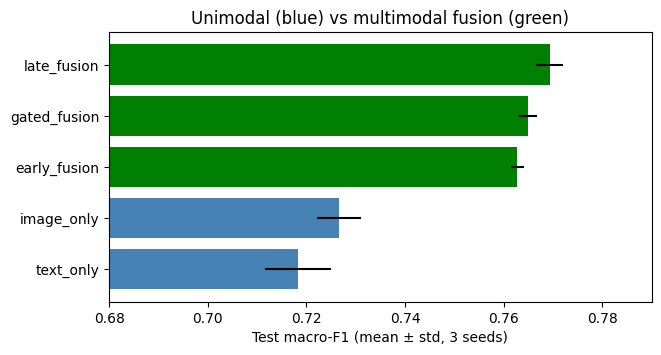

late_fusion vs text_only: McNemar p = 0.0007


In [ ]:
# Results table (mean ± std over 3 seeds)
rows = []
for name, runs in RESULTS.items():
    m = pd.DataFrame([metrics(Y["test"], r["test"]) for r in runs])
    rows.append({"model": name, **{k: f"{m[k].mean():.3f} ± {m[k].std():.3f}" for k in m}})
TABLE = pd.DataFrame(rows).set_index("model")
display(TABLE); TABLE.to_csv(OUT / "tables" / "results.csv")

# Bar chart of macro-F1
f1 = {n: [metrics(Y["test"], r["test"])["macro_f1"] for r in runs] for n, runs in RESULTS.items()}
names = sorted(f1, key=lambda n: np.mean(f1[n]))
plt.figure(figsize=(7, 3.5))
plt.barh(names, [np.mean(f1[n]) for n in names], xerr=[np.std(f1[n]) for n in names],
         color=["green" if "fusion" in n else "steelblue" for n in names])
plt.xlim(0.68, 0.79); plt.xlabel("Test macro-F1 (mean ± std, 3 seeds)")
plt.title("Unimodal (blue) vs multimodal fusion (green)")
savefig("results_comparison")

# McNemar test: best fusion vs text-only
from scipy.stats import binomtest
best = max([n for n in RESULTS if "fusion" in n], key=lambda n: np.mean(f1[n]))
a = (RESULTS[best][0]["test"] >= 0.5) == Y["test"]
b = (RESULTS["text_only"][0]["test"] >= 0.5) == Y["test"]
n01, n10 = (a & ~b).sum(), (~a & b).sum()
print(f"{best} vs text_only: McNemar p = {binomtest(min(n01, n10), n01 + n10).pvalue:.4f}")

## Overfitting: learning curves + train/dev/test gap

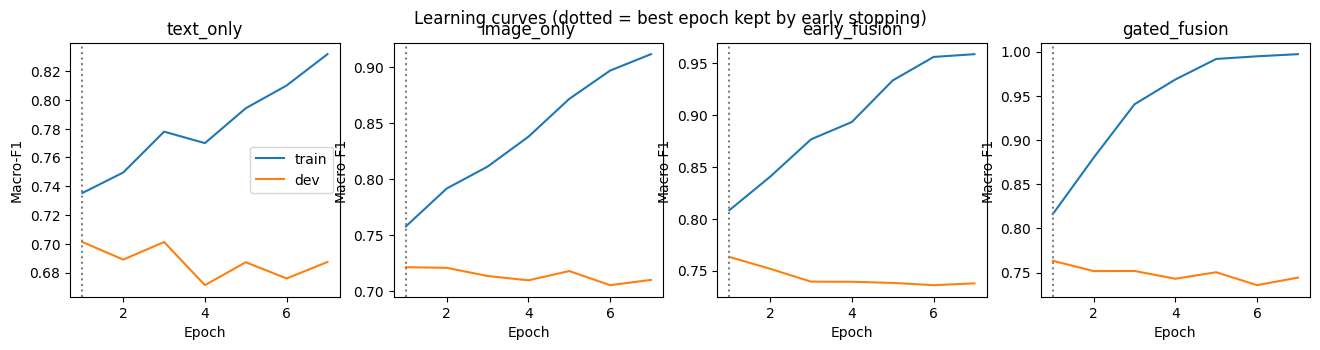

,train,dev,test,train_minus_test
text_only,0.741604,0.702923,0.718260,0.023344
image_only,0.781214,0.723888,0.726627,0.054587
early_fusion,0.808794,0.763487,0.762765,0.046029
gated_fusion,0.867197,0.761058,0.765031,0.102166
late_fusion,0.815112,0.756043,0.769307,0.045805


In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.3))
for a_, name in zip(ax, HIST):
    h = HIST[name][0]
    a_.plot(h.epoch, h.train_f1, label="train"); a_.plot(h.epoch, h.dev_f1, label="dev")
    a_.axvline(h.dev_f1.idxmax() + 1, color="grey", ls=":"); a_.set(title=name, xlabel="Epoch", ylabel="Macro-F1")
ax[0].legend(); fig.suptitle("Learning curves (dotted = best epoch kept by early stopping)"); savefig("learning_curves")

gap = pd.DataFrame({n: {s: np.mean([metrics(Y[s], r[s])["macro_f1"] for r in runs]) for s in S} for n, runs in RESULTS.items()}).T
gap["train_minus_test"] = gap.train - gap.test
display(gap); gap.to_csv(OUT / "tables" / "overfitting.csv")


## Confusion matrices + ROC curves

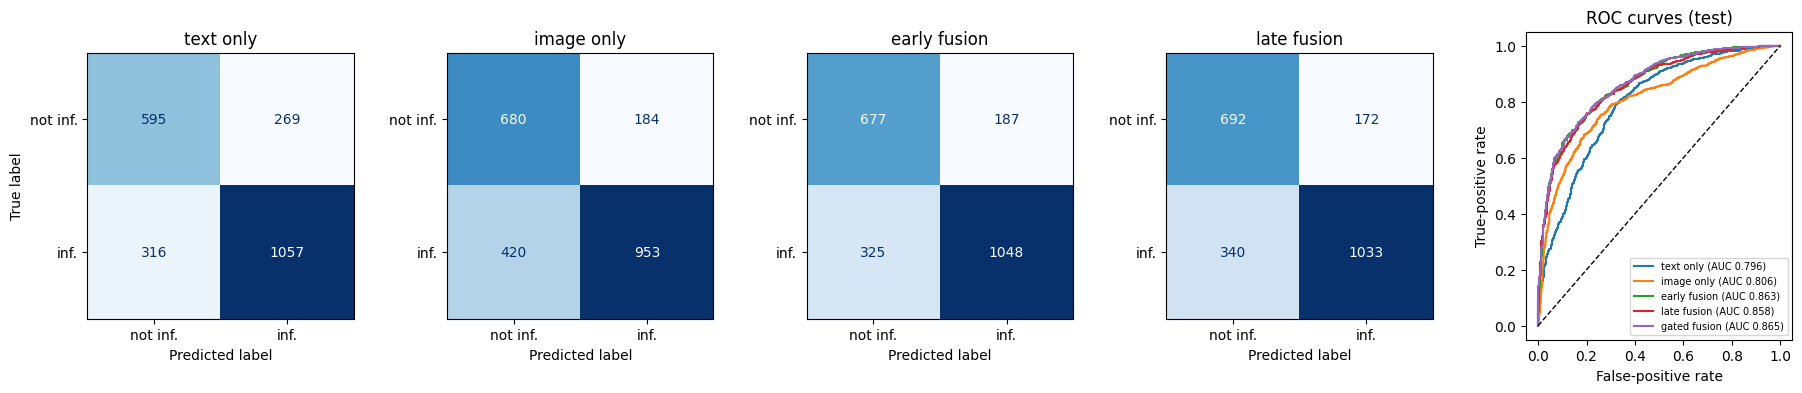

In [ ]:
show = ["text_only", "image_only", "early_fusion", "late_fusion"]
fig, ax = plt.subplots(1, 5, figsize=(22, 4), gridspec_kw={"wspace": 0.35})
for a_, name in zip(ax, show):
    skm.ConfusionMatrixDisplay.from_predictions(Y["test"], (RESULTS[name][0]["test"] >= .5).astype(int),
        display_labels=["not inf.", "inf."], cmap="Blues", ax=a_, colorbar=False)
    a_.set_title(name.replace("_", " ")); a_.grid(False)
    if a_ is not ax[0]: a_.set_ylabel("")
for name in show + ["gated_fusion"]:
    fpr, tpr, _ = skm.roc_curve(Y["test"], RESULTS[name][0]["test"])
    ax[-1].plot(fpr, tpr, label=f"{name.replace('_', ' ')} (AUC {skm.roc_auc_score(Y['test'], RESULTS[name][0]['test']):.3f})")
ax[-1].plot([0, 1], [0, 1], "k--", lw=1)
ax[-1].set(xlabel="False-positive rate", ylabel="True-positive rate", title="ROC curves (test)"); ax[-1].legend(fontsize=7, loc="lower right")
savefig("confusion_roc")

## Generalisation & bias: performance per disaster event

,text_only,image_only,early_fusion,late_fusion,n_test
hurricane_harvey,0.705563,0.706298,0.760180,0.758705,568
hurricane_irma,0.670800,0.688345,0.703012,0.703686,548
hurricane_maria,0.735838,0.711926,0.766991,0.763012,542
california_wildfires,0.704716,0.722982,0.726251,0.752786,240
mexico_earthquake,0.690260,0.778805,0.829728,0.803929,159
srilanka_floods,0.900926,0.816467,0.850045,0.884157,107
iraq_iran_earthquake,0.549745,0.742555,0.701913,0.739750,73


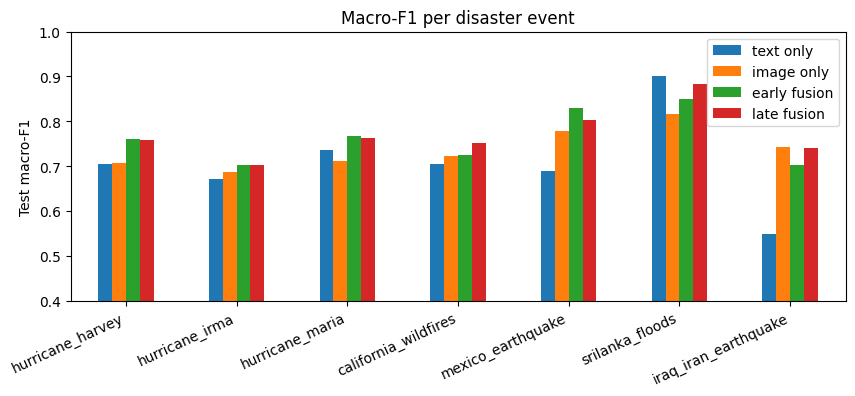

In [ ]:
per_event = pd.DataFrame({name: {e: metrics(Y["test"][i], RESULTS[name][0]["test"][i])["macro_f1"]
                                 for e, i in S["test"].groupby("event").indices.items()} for name in show})
per_event["n_test"] = S["test"].event.value_counts(); per_event = per_event.sort_values("n_test", ascending=False)
display(per_event); per_event.to_csv(OUT / "tables" / "per_event.csv")
per_event.drop(columns="n_test").rename(columns=lambda c: c.replace("_", " ")).plot.bar(figsize=(10, 3.5)); plt.ylim(0.4, 1); plt.ylabel("Test macro-F1")
plt.xticks(rotation=25, ha="right"); plt.title("Macro-F1 per disaster event"); savefig("per_event")


## Error analysis (failure cases)

In [ ]:

d = S["test"].copy()
d["p_text"]   = RESULTS["text_only"][0]["test"]
d["p_image"]  = RESULTS["image_only"][0]["test"]
d["p_fusion"] = RESULTS[best][0]["test"]

text_ok   = (d.p_text   >= 0.5) == d.y
image_ok  = (d.p_image  >= 0.5) == d.y
fusion_ok = (d.p_fusion >= 0.5) == d.y

# 1) Did fusion help compared with text only?
print("Fusion fixed text mistakes:", (fusion_ok & ~text_ok).sum())
print("Fusion broke correct text predictions:", (~fusion_ok & text_ok).sum())

# 2) Fusion accuracy when the text and image models agree or disagree
d["case"] = np.where(text_ok & image_ok, "both right",
            np.where(text_ok, "only text right",
            np.where(image_ok, "only image right", "both wrong")))
table = d.assign(fusion_ok=fusion_ok).groupby("case").fusion_ok.agg(posts="size", fusion_accuracy="mean")
display(table); table.to_csv(OUT / "tables" / "error_breakdown.csv")

# 3) The 10 most confident mistakes (text only, no images)
cols = ["event", "label", "text_clean", "p_text", "p_image", "p_fusion"]
fails = d[~fusion_ok].assign(confidence=(d.p_fusion - 0.5).abs()).nlargest(10, "confidence")
display(fails[cols]); fails[cols].to_csv(OUT / "tables" / "failure_cases.csv", index=False)

# 4) Save all tables and figures
import shutil; shutil.make_archive("/content/outputs_for_report", "zip", OUT)
from google.colab import files; files.download("/content/outputs_for_report.zip")

Fusion fixed text mistakes: 262
Fusion broke correct text predictions: 189


,posts,fusion_accuracy
case,,
both right,1280,1.000000
both wrong,232,0.000000
only image right,353,0.742210
only text right,372,0.491935


,event,label,text_clean,p_text,p_image,p_fusion
1709,hurricane_maria,informative,Describing our week in three words: Fuerza Pue...,0.066306,0.081065,0.074423
801,hurricane_harvey,informative,Texans plan to honor Harvey heroes at Sunday's...,0.117496,0.083772,0.098948
111,hurricane_maria,informative,Thank you to everyone who came last night and ...,0.146364,0.086199,0.113273
1609,hurricane_irma,informative,Live Irma Update on LashanaMarie Beauty | Blac...,0.089646,0.141608,0.118225
1972,hurricane_irma,informative,Back to work post-Irma in my Studio Physics cl...,0.044248,0.190164,0.124502
823,hurricane_maria,not_informative,11 pm advisory is in for Hurricane Maria. Fore...,0.862678,0.875166,0.869547
158,mexico_earthquake,not_informative,How many tragedies! Livorno Irma Hurricane har...,0.755989,0.951690,0.863625
373,hurricane_irma,informative,Meet Irma!! The go-to LulaRoe top. It is loose...,0.044327,0.221685,0.141874
660,hurricane_harvey,informative,Harvey Hair... Don't Care! Day on 9/15. Donate...,0.058073,0.216977,0.145470
636,hurricane_irma,informative,IRMA NFL : Greg Olsen suffers broken foot: (vi...,0.150455,0.148131,0.149177


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>